# Source understanding, availability and quality

All data is synthetic. This notebook checks analytical grain, source availability, duplicates, quarantine and reconciliation before interpreting business metrics.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'tvads').exists(): ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from tvads.pipeline import current_output
OUT=current_output()
REPORTS=OUT/'reports'
summary=json.loads((REPORTS/'summary.json').read_text())
manifest=json.loads((OUT/'run_manifest.json').read_text())
fact=pd.read_parquet(OUT/'fact_commitments.parquet')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Synthetic snapshot:',summary['as_of'])


Synthetic snapshot: 2026-07-15T00:00:00Z


In [2]:
from tvads.warehouse import read_raw
raw=read_raw(OUT/'raw')
pd.DataFrame([{'source':k,'rows':len(v),'columns':len(v.columns)} for k,v in raw.items()])

            source   rows  columns
0      advertisers     30        3
1        campaigns    120        6
2         stations     24        5
3    booking_lines    360        7
4      commitments  18000        5
5  scheduled_spots  18737       10
6      airing_logs  18217        8
7    invoice_lines  16732        9
8          credits    408        6

## Grain and relationships

A source event may be replayed, and a commitment may have multiple schedules, airings and invoices. Raw row counts are not interchangeable with contracted units.

In [3]:
assert fact.commitment_id.is_unique
raw_keys={'advertisers':'advertiser_id','campaigns':'campaign_id','stations':'station_id','booking_lines':'booking_line_id','commitments':'commitment_id','scheduled_spots':'scheduled_spot_id','airing_logs':'ingestion_id','invoice_lines':'invoice_line_id','credits':'credit_id'}
pd.DataFrame([{'source':k,'key':v,'unique':raw[k][v].is_unique,'null_cells':int(raw[k].isna().sum().sum())} for k,v in raw_keys.items()])

            source                key  unique  null_cells
0      advertisers      advertiser_id    True           0
1        campaigns        campaign_id    True           0
2         stations         station_id    True           0
3    booking_lines    booking_line_id    True           0
4      commitments      commitment_id    True           0
5  scheduled_spots  scheduled_spot_id    True           0
6      airing_logs       ingestion_id    True           0
7    invoice_lines    invoice_line_id    True           0
8          credits          credit_id    True           0

In [4]:
pd.DataFrame(manifest['validation']['quarantine_candidates'].items(),columns=['Source issue','Raw rows'])

              Source issue  Raw rows
0  unmatched_schedule_rows         1
1   unmatched_invoice_rows         1
2    unmatched_credit_rows         1

## Source event replay and conflict handling

Identical factual payloads for one source event count once. Conflicting payloads are ambiguous and cannot establish delivery. Feed defects remain visible in an audit queue.

In [5]:
airings=pd.read_csv(OUT/'tableau_ready/fact_airing_review.csv')
assert airings.source_event_id.is_unique
quality=airings.airing_status.value_counts().rename_axis('airing_status').reset_index(name='canonical_events')
quality

        airing_status  canonical_events
0          qualifying             17076
1          off_window               324
2      wrong_creative               135
3      wrong_duration               112
4     conflicting_log                89
5    cancelled_airing                75
6  unmatched_schedule                 1

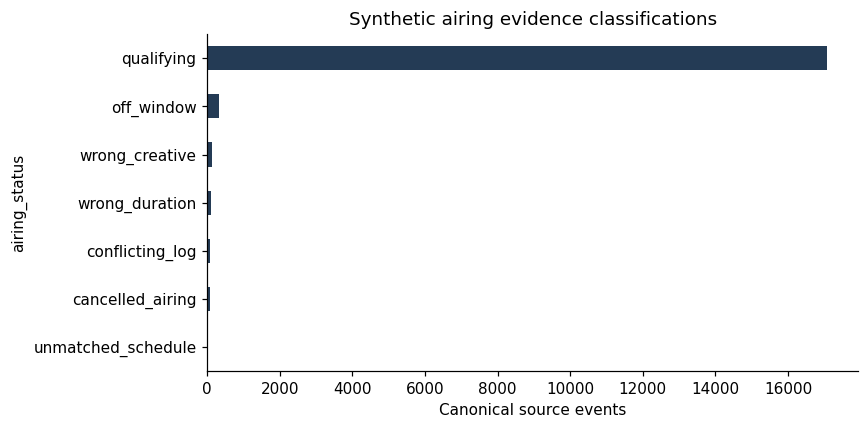

In [6]:
quality.set_index('airing_status').canonical_events.sort_values().plot.barh(figsize=(8,4),color='#243B55')
plt.xlabel('Canonical source events');plt.title('Synthetic airing evidence classifications');plt.tight_layout();plt.show()

In [7]:
pd.DataFrame([{'measure':'Raw visible feed rows','count':int(airings.raw_record_count.sum())},{'measure':'Unique source events','count':len(airings)},{'measure':'Replay/conflict rows beyond first','count':int(airings.raw_record_count.sum()-len(airings))}])

                             measure  count
0              Raw visible feed rows  18217
1               Unique source events  17812
2  Replay/conflict rows beyond first    405

## Arrival latency

A valid airing can look absent until its source record arrives. These delays are configured simulation outcomes, not measured broadcaster SLAs.

In [8]:
logs=raw['airing_logs'].copy()
logs['latency_hours']=(pd.to_datetime(logs.ingested_at,utc=True)-pd.to_datetime(logs.aired_at,utc=True)).dt.total_seconds()/3600
logs.latency_hours.describe(percentiles=[0.5,0.9,0.99])

count    18217.000000
mean        10.825821
std         20.590256
min          1.000000
50%          3.000000
90%         13.000000
99%         72.000000
max         73.000000
Name: latency_hours, dtype: float64

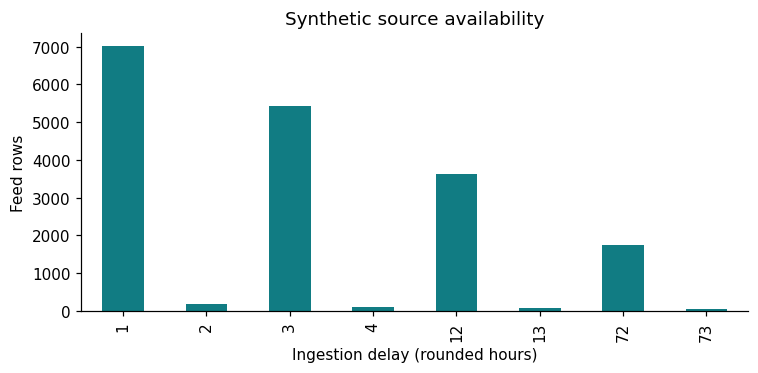

In [9]:
logs.groupby(logs.latency_hours.round().astype(int)).size().plot.bar(figsize=(7,3.5),color='#117C83')
plt.xlabel('Ingestion delay (rounded hours)');plt.ylabel('Feed rows');plt.title('Synthetic source availability');plt.tight_layout();plt.show()

## Station local time and daylight saving

The contract uses local station flight dates/dayparts. The warehouse stores UTC timestamps. Validation checks both original and replacement schedules.

In [10]:
example=raw['scheduled_spots'].merge(raw['stations'][['station_id','timezone']],on='station_id',validate='many_to_one').head(8).copy()
example['local_scheduled_time']=[pd.Timestamp(t).tz_convert(z).isoformat() for t,z in zip(example.scheduled_at,example.timezone)]
example[['scheduled_spot_id','scheduled_at','timezone','local_scheduled_time']]

  scheduled_spot_id  ...       local_scheduled_time
0        C0000001-O  ...  2026-02-01T15:20:00-08:00
1        C0000002-O  ...  2026-02-05T20:20:00-05:00
2        C0000003-O  ...  2026-02-13T00:20:00-05:00
3        C0000004-O  ...  2026-02-09T07:20:00-06:00
4        C0000005-O  ...  2026-02-11T19:20:00-06:00
5        C0000006-O  ...  2026-02-22T07:20:00-06:00
6        C0000007-O  ...  2026-05-06T01:20:00-06:00
7        C0000008-O  ...  2026-05-05T07:20:00-05:00

[8 rows x 4 columns]

## Independent count and money controls

All differences must be zero. Orphan invoices and unapplied orphan credits are included in complete-ledger controls instead of silently disappearing.

In [11]:
controls=pd.read_csv(REPORTS/'reconciliation_controls.csv')
assert controls.status.eq('MATCH').all()
controls

                                control  source_value  ...           unit  status
0                      commitment_grain         18000  ...    commitments   MATCH
1                       due_commitments         17438  ...    commitments   MATCH
2                visible_airing_records         18217  ...    source rows   MATCH
3               canonical_airing_events         17812  ...         events   MATCH
4                 visible_invoice_lines         16732  ...  invoice lines   MATCH
5                        gross_invoices     301539914  ...      USD cents   MATCH
6                 applied_credit_amount        610500  ...      USD cents   MATCH
7  full_ledger_net_including_quarantine     300928414  ...      USD cents   MATCH
8                matched_billing_bridge     300917069  ...      USD cents   MATCH
9             expected_to_billed_bridge     300917069  ...      USD cents   MATCH

[10 rows x 6 columns]

## Synthetic oracle evaluation

The generator records injected defect identities and expected root outcomes separately. Those oracle files do not enter SQL or estimation. Perfect scores apply only to this known constructed scenario.

In [12]:
summary['oracle_evaluation']

{'scope': 'Known injected synthetic defects at final observation cutoff only', 'expected_exceptions': 8988, 'detected_exceptions': 8988, 'true_positives': 8988, 'false_positives': 0, 'false_negatives': 0, 'precision': 1.0, 'recall': 1.0, 'commitment_oracle': 'MATCH', 'unexpected': [], 'missed': []}